# EDA Task 2: Toxicity Classification

Data fusion Jigsaw (komentar Wikipedia, 6 kategori) + CONDA (chat Dota 2, intent) untuk DistilRoBERTa 7 output (gate + 6 kategori).

## Setup

In [1]:
# Imports and Paths
import csv
import json
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

repo = Path.cwd()
while not (repo / "pyproject.toml").exists():
    repo = repo.parent
sys.path.insert(0, str(repo / "src" / "task_2"))

from config import CATS, OUT, RUNS, TOXIC_INTENTS

RAW = repo / "data" / "raw"
JIGSAW = RAW / "jigsaw"
HAS_JIGSAW = (JIGSAW / "train.csv").exists()
RUN = "e2_mix"
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 90)
print("Jigsaw lokal:", HAS_JIGSAW)

Jigsaw lokal: False


In [2]:
# Plot Style
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#b4b2ab", "#e34948"]
INK, MUTED, GRID = "#0b0b0b", "#6b6a65", "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.labelcolor": MUTED,
    "legend.frameon": False,
})

In [3]:
# Task 2 Sets
# CONDA dan NoisyHate dari prepare.py (tidak butuh Jigsaw), Jigsaw hanya jika ada
import prepare
from common import load_set

if not (OUT / "conda_bench.tsv").exists():
    prepare.prepare_conda()
    prepare.prepare_noisyhate()
if HAS_JIGSAW and not (OUT / "jigsaw_test.tsv").exists():
    prepare.prepare_jigsaw()

## 1. Sumber Data

| Dataset | Isi | Sumber | Peran |
| --- | --- | --- | --- |
| Jigsaw Toxic Comment Classification | Komentar Wikipedia, 6 label biner | Kaggle `jigsaw-toxic-comment-classification-challenge` (`train.csv`, `test.csv`, `test_labels.csv`) | Gate + kategori. Train dipecah 95/5 jadi train/dev, test hanya baris berlabel |
| CONDA | Chat Dota 2, intent per baris CSV | `usydnlp/CONDA` | Gate. E/I toksik, A/O bukan. Split match-level ikut Task 1 |
| NoisyHate | Komentar toksik tersamar | `NoisyHate/Noisy_Hate_Data` | Uji ketahanan penyamaran |

Jigsaw tidak disimpan di git. Taruh tiga CSV di `data/raw/jigsaw/` untuk menjalankan bagian Jigsaw.

## 2. Jigsaw

In [4]:
# Jigsaw Overview
if HAS_JIGSAW:
    jig = {s: load_set(f"jigsaw_{s}") for s in ["train", "dev", "test"]}
    tab = pd.DataFrame({s: {"baris": len(d), "gate+": d["gate"].mean(), **{c: d[c].mean() for c in CATS}}
                        for s, d in jig.items()}).T
    display(tab)
else:
    # angka dari output prepare.py di notebook Colab Task 2
    display(pd.DataFrame({"baris": [151592, 7979, 63978], "gate+": [0.101, 0.106, 0.098]},
                         index=["train", "dev", "test"]))

,baris,gate+
train,151592,0.101
dev,7979,0.106
test,63978,0.098


In [5]:
# Jigsaw Labels and Lengths
if HAS_JIGSAW:
    tr = jig["train"]
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
    rate = tr[CATS].mean().sort_values()
    axes[0].barh(rate.index, rate.values * 100, color=SERIES[0])
    axes[0].set_title("Porsi label per kategori (train, %)")
    lens = tr["text"].str.split().str.len()
    axes[1].hist(lens.clip(upper=300), bins=60, color=SERIES[1])
    axes[1].set_title(f"Panjang komentar (kata), median {lens.median():.0f}")
    fig.tight_layout()
    co = tr[CATS].T.dot(tr[CATS])
    display(co)

## 3. CONDA untuk Task 2

In [6]:
# CONDA Splits
conda = {s: load_set(f"conda_{s}") for s in ["train", "dev", "bench"]}
rows = []
for s, d in conda.items():
    rows.append({"split": s, "baris": len(d), "match": d["match_id"].nunique(), "gate+": d["gate"].mean(),
                 **d["intent"].value_counts().to_dict(),
                 "kata median": d["raw"].str.split().str.len().median()})
pd.DataFrame(rows).set_index("split")

,baris,match,gate+,O,E,A,I,kata median
split,,,,,,,,
train,28965,1533,0.192,21492,3733,1901,1839,2.0
dev,3500,192,0.204,2579,505,206,210,2.0
bench,3422,192,0.204,2532,473,192,225,2.0


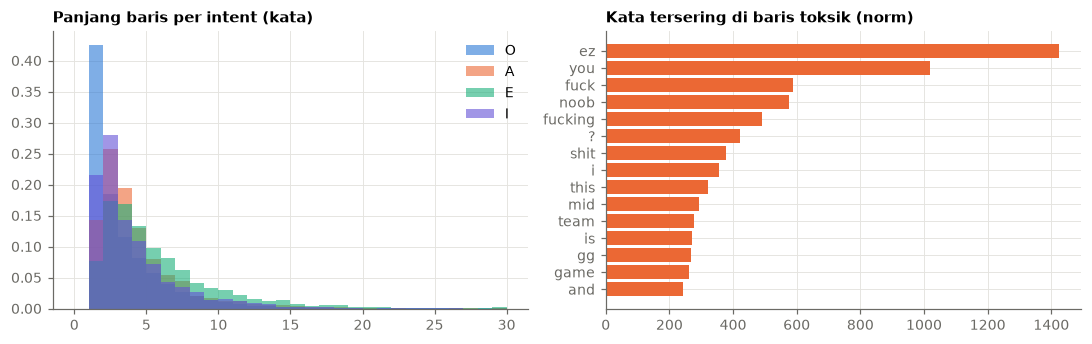

In [7]:
# CONDA Intent and Lengths
d = conda["train"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for k, color in zip(["O", "A", "E", "I"], SERIES):
    lens = d.loc[d["intent"] == k, "raw"].str.split().str.len().clip(upper=30)
    axes[0].hist(lens, bins=range(0, 31), alpha=0.6, label=k, color=color, density=True)
axes[0].set_title("Panjang baris per intent (kata)")
axes[0].legend()
words = Counter(w for t in d.loc[d["gate"] == 1, "norm"] for w in t.split())
top = words.most_common(15)[::-1]
axes[1].barh([w for w, _ in top], [c for _, c in top], color=SERIES[1])
axes[1].set_title("Kata tersering di baris toksik (norm)")
fig.tight_layout()

In [8]:
# CONDA Examples
d.groupby("intent").sample(4, random_state=1)[["intent", "raw", "norm"]]

,intent,raw,norm
6030,A,you should leave wsilencer and we remake deal ?,you should leave silencer and we remake deal ?
2903,A,report,report
18492,A,1 more min,1 more min
20775,A,if you dont want him on your team i suggust reporting him,if you don't want him on your team i suggust reporting him
24938,E,fuck you,fuck you
22990,E,shit,shit
14184,E,ooohhh fuck,ooohhh fuck
10931,E,too ez get raped by frenchie shame,too ez get raped by frenchie shame
8729,I,ezi es,ezi es
11614,I,don;t expect me to win mid' direct quote from invoker,don't expect me to win mid ' direct quote from invoker


## 4. Contoh Data Latih

Satu contoh = teks + target 7 output + mask loss. Kategori Jigsaw tidak ada di CONDA, jadi di-mask untuk CONDA toksik.
CONDA dipakai dua kali per baris (teks `norm` dan `raw`). Negatif Jigsaw disampel 35%.

In [9]:
# Training Examples
from common import build_train

cfg = json.loads((RUNS / RUN / "config.json").read_text())
texts, Y, M = build_train(["conda"], ["norm", "raw"], cfg["jigsaw_neg_frac"], cfg["seed"])
idx = [i for i in range(len(texts)) if Y[i, 0] == 1][:3] + [i for i in range(len(texts)) if Y[i, 0] == 0][:2]
pd.DataFrame({"teks": [texts[i] for i in idx], "target": [Y[i].astype(int).tolist() for i in idx],
              "mask": [M[i].astype(int).tolist() for i in idx]})

,teks,target,mask
0,pudge smoke in 1k mmr are you a fucking joke,"[1, 0, 0, 0, 0, 0, 0]","[1, 0, 0, 0, 0, 0, 0]"
1,not to take anything away from you but i doubt its hard to outplay a retard,"[1, 0, 0, 0, 0, 0, 0]","[1, 0, 0, 0, 0, 0, 0]"
2,"i blame disruptor , he was shit","[1, 0, 0, 0, 0, 0, 0]","[1, 0, 0, 0, 0, 0, 0]"
3,jajajaja,"[0, 0, 0, 0, 0, 0, 0]","[1, 1, 1, 1, 1, 1, 1]"
4,clockwerk is close to 3 .,"[0, 0, 0, 0, 0, 0, 0]","[1, 1, 1, 1, 1, 1, 1]"


In [10]:
# Training Mix
print("contoh latih e2_mix:", cfg["n_train"])
print("CONDA (norm + raw):", len(texts))
print("Jigsaw (setelah sampling negatif):", cfg["n_train"] - len(texts))

contoh latih e2_mix: 121221
CONDA (norm + raw): 57930
Jigsaw (setelah sampling negatif): 63291
